# Genomic associations of drug response and CRISPR-Cas9 gene essentiality in cancer cell lines

Proof of concept for `cmix`: a systematic association scan of **678 binary genomic features**
(270 driver mutations, 407 recurrent copy-number gains/losses and MSI status) against

1. **drug response**: GDSC1/GDSC2 ln(IC50) of 819 drugs in up to ~990 cell lines, and
2. **CRISPR-Cas9 gene essentiality**: integrated Sanger + Broad gene effects of 17,486 genes in 537 cell lines.

Every (phenotype, feature) pair is tested twice: with an ordinary **linear model** (LM) and with a
**linear mixed model** (LMM) whose random effect uses a kinship matrix built from the genomic
features. The kinship captures the overall genomic similarity between cell lines (which largely
tracks tissue of origin), so the LMM reduces spurious associations driven by lineage.
Every scan is timed.

Data: public deposit of the MOSA paper (Cai *et al.*, Nat Commun 2024;
[figshare 24420580](https://doi.org/10.6084/m9.figshare.24420580)).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cmix
import cmix.plot  # applies the default figure style on import
from cmix.plot import GREY, RED

DATA = "/data/tmpC/mosa-disentangle/data/raw/figshare_24420580/"
timings = {}

## Data

All matrices are oriented samples x features (cell lines are identified by Cell Model Passports ids).

In [2]:
genomics = pd.read_csv(DATA + "genomics.csv", index_col=0).T  # cell lines x binary features
drug = pd.read_csv(DATA + "drugresponse.csv", index_col=0).T  # cell lines x drugs, ln(IC50)
crispr = pd.read_csv(DATA + "crisprcas9.csv", index_col=0).T  # cell lines x genes, gene effect
samplesheet = pd.read_csv(DATA + "samplesheet.csv", index_col=0)
institute = pd.read_csv(DATA + "crisprcas9_institute.csv", index_col=0)["source"]

feature_type = pd.Series(
    np.where(genomics.columns.str.endswith("_mut"), "mutation",
             np.where(genomics.columns.str.contains("cna"), "copy number", "other")),
    index=genomics.columns,
)
print(f"genomics: {genomics.shape}  {feature_type.value_counts().to_dict()}")
print(f"drug response: {drug.shape}, {drug.isna().mean().mean():.0%} missing")
print(f"CRISPR-Cas9: {crispr.shape}, {crispr.isna().mean().mean():.2%} missing")

genomics: (994, 678)  {'copy number': 407, 'mutation': 270, 'other': 1}
drug response: (995, 819), 26% missing
CRISPR-Cas9: (537, 17486), 0.05% missing


## Kinship and covariates

The kinship matrix is the realised relationship matrix of the standardised genomic features
(`K = X Xᵀ / p`, diagonal normalised to a mean of one). Clustering the heatmap shows blocks of
related cell lines, and lines from the same tissue are on average slightly more related than lines
from different tissues: this lineage structure is what the random effect absorbs.

Covariates are an intercept and growth properties (adherent as reference). The CRISPR scans
also include the screening institute (Broad versus Sanger).

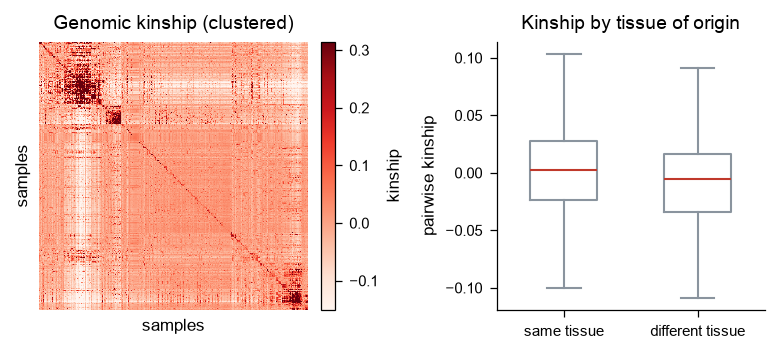

In [3]:
K = cmix.kinship(genomics)

tissue = samplesheet["tissue"].reindex(genomics.index)
same = np.equal.outer(tissue.to_numpy(), tissue.to_numpy())
off_diag = ~np.eye(len(K), dtype=bool)
k_values = K.to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(5.4, 2.4), gridspec_kw={"width_ratios": [1.25, 1]})
cmix.plot.kinship(K, cluster=True, ax=axes[0])
axes[0].set_title("Genomic kinship (clustered)")
axes[1].boxplot(
    [k_values[same & off_diag], k_values[~same & off_diag]],
    tick_labels=["same tissue", "different tissue"], widths=0.5, showfliers=False,
    medianprops={"color": RED}, boxprops={"color": GREY}, whiskerprops={"color": GREY},
    capprops={"color": GREY},
)
axes[1].set_ylabel("pairwise kinship")
axes[1].set_title("Kinship by tissue of origin")
plt.tight_layout()

In [4]:
growth = samplesheet["growth_properties"].reindex(genomics.index).fillna("Unknown")
covariates = pd.get_dummies(growth, prefix="growth", dtype=float).drop(columns="growth_Adherent")
covariates.insert(0, "intercept", 1.0)
covariates.head()

,intercept,growth_Semi-Adherent,growth_Suspension,growth_Unknown
SIDM00055,1.0,0.0,0.0,1.0
SIDM00499,1.0,0.0,0.0,0.0
SIDM00980,1.0,0.0,0.0,0.0
SIDM00982,1.0,0.0,0.0,0.0
SIDM01240,1.0,0.0,0.0,0.0


## Drug response

Each drug is a phenotype with its own set of screened cell lines (`NaN` elsewhere); `cmix.scan`
analyses each drug on its observed samples. Only genomic features present in at least 10 of the
analysed cell lines are tested.

In [5]:
samples = drug.index.intersection(genomics.index)
Y_drug = drug.loc[samples]
G_drug = genomics.loc[samples].loc[:, genomics.loc[samples].sum() >= 10]
M_drug = covariates.loc[samples]
K_drug = K.loc[samples, samples]
print(f"{len(samples)} cell lines, {G_drug.shape[1]} genomic features, {Y_drug.shape[1]} drugs")

991 cell lines, 529 genomic features, 819 drugs


In [6]:
start = time.perf_counter()
drug_lm = cmix.scan(Y_drug, G_drug, M=M_drug)
timings["drug response, LM"] = time.perf_counter() - start

start = time.perf_counter()
drug_lmm = cmix.scan(Y_drug, G_drug, K=K_drug, M=M_drug)
timings["drug response, LMM"] = time.perf_counter() - start

print(drug_lm, drug_lmm, sep="\n\n")

ScanResult: 819 phenotype(s) x 529 variant(s) in 1.59 s
  linear model (no kinship)
  smallest p-value: 1.53e-95

ScanResult: 819 phenotype(s) x 529 variant(s) in 32.85 s
  h2 (median): 0.084
  smallest p-value: 4.69e-59


### Calibration and variance components

The quantile-quantile plot pools the p-values of all drugs. The LM shows a broad excess of small
p-values (inflation), a large part of which comes from the lineage structure: a feature that marks
a tissue is associated with every drug to which that tissue is sensitive. The LMM random effect
absorbs this and the pooled distribution gets closer to the uniform expectation while the
strongest hits remain. The histogram shows the share of each drug's variance attributed to the
kinship (`h2`).

,tests,Bonferroni hits (5%),fraction p < 1e-3,median -log10 p / expected
LM,430416.0,224.0,0.011150,1.310202
LMM,430416.0,119.0,0.003111,0.982270


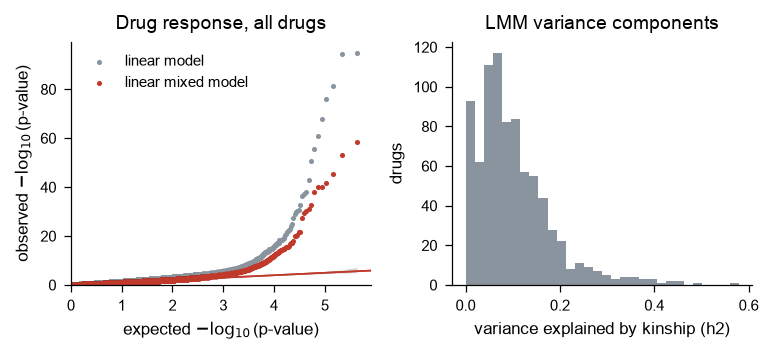

In [7]:
def flat(result):
    pv = result.pvalue.to_numpy().ravel()
    return pv[np.isfinite(pv)]


def summarise(results):
    rows = {}
    for name, result in results.items():
        pv = flat(result)
        rows[name] = {
            "tests": pv.size,
            "Bonferroni hits (5%)": int((pv < 0.05 / pv.size).sum()),
            "fraction p < 1e-3": (pv < 1e-3).mean(),
            "median -log10 p / expected": np.median(-np.log10(pv)) / -np.log10(0.5),
        }
    return pd.DataFrame(rows).T


fig, axes = plt.subplots(1, 2, figsize=(5.2, 2.4))
cmix.plot.qqplot(flat(drug_lm), ax=axes[0], label="linear model", color=GREY)
cmix.plot.qqplot(flat(drug_lmm), ax=axes[0], label="linear mixed model", color=RED)
axes[0].set_title("Drug response, all drugs")
axes[1].hist(drug_lmm.variances["h2"].dropna(), bins=30, color=GREY)
axes[1].set_xlabel("variance explained by kinship (h2)")
axes[1].set_ylabel("drugs")
axes[1].set_title("LMM variance components")
plt.tight_layout()
summarise({"LM": drug_lm, "LMM": drug_lmm})

### Strongest associations

The top LMM associations recover textbook pharmacogenomic markers (BRAF mutation with BRAF/MEK
inhibitors, TP53 mutation with MDM2 inhibitors such as Nutlin-3a, and so on). The scatter compares
the two models test by test: most p-values shrink under the LMM, the strongest effects survive.

In [8]:
top_drug = (
    drug_lmm.stats.dropna()
    .sort_values("pvalue")
    .assign(pvalue_lm=lambda d: drug_lm.pvalue.to_numpy().ravel(order="F")[d.index])
    .head(15)
    .reset_index(drop=True)
)
top_drug

,phenotype,variant,beta,beta_se,lrt,pvalue,n,pvalue_lm
0,1373;Dabrafenib;GDSC1,BRAF_mut,-4.449921,0.254813,262.585209,4.688273e-59,866.0,2.991507e-95
1,1373;Dabrafenib;GDSC2,BRAF_mut,-3.950204,0.241050,238.130784,1.005274e-53,969.0,1.528954e-95
2,1371;PLX-4720;GDSC1,BRAF_mut,-2.311201,0.154071,202.314063,6.529287e-46,921.0,1.408393e-68
3,1036;PLX-4720;GDSC1,BRAF_mut,-2.252009,0.157098,186.749986,1.628435e-42,940.0,1.392209e-61
4,1047;Nutlin-3a (-);GDSC2,TP53_mut,1.800524,0.128945,178.687315,9.376450e-41,982.0,5.108403e-82
5,1061;SB590885;GDSC1,BRAF_mut,-2.107647,0.150438,178.526250,1.016733e-40,904.0,3.415674e-56
6,1047;Nutlin-3a (-);GDSC1,TP53_mut,1.306531,0.096273,169.056207,1.189334e-38,943.0,7.622806e-77
7,1036;PLX-4720;GDSC2,BRAF_mut,-2.550754,0.204943,144.377442,2.938120e-33,967.0,1.498660e-51
8,1061;SB590885;GDSC2,BRAF_mut,-1.990101,0.163610,138.285007,6.313337e-32,961.0,1.671303e-43
9,2296;GDC-0879;GDSC2,BRAF_mut,-2.256901,0.184624,134.566010,4.108328e-31,606.0,4.721215e-37


Text(0.5, 1.0, 'Drug response associations')

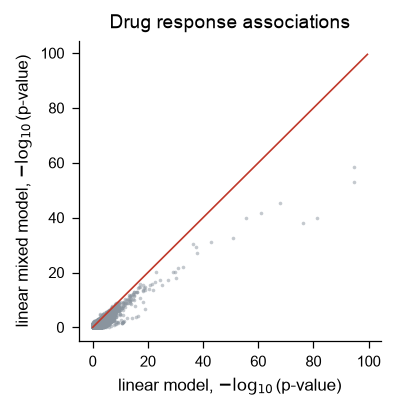

In [9]:
pv_lm = -np.log10(drug_lm.pvalue.to_numpy().ravel())
pv_lmm = -np.log10(drug_lmm.pvalue.to_numpy().ravel())
ok = np.isfinite(pv_lm) & np.isfinite(pv_lmm)

fig, ax = plt.subplots(figsize=(2.6, 2.6))
ax.scatter(pv_lm[ok], pv_lmm[ok], s=3, lw=0, color=GREY, alpha=0.5, rasterized=True)
lim = max(pv_lm[ok].max(), pv_lmm[ok].max()) * 1.05
ax.plot([0, lim], [0, lim], color=RED, lw=0.8)
ax.set_xlabel(r"linear model, $-\log_{10}$(p-value)")
ax.set_ylabel(r"linear mixed model, $-\log_{10}$(p-value)")
ax.set_title("Drug response associations")

### Manhattan plots

Features are grouped by type (mutation, copy number, other). Red points pass the Bonferroni
threshold for the number of features tested for that drug.

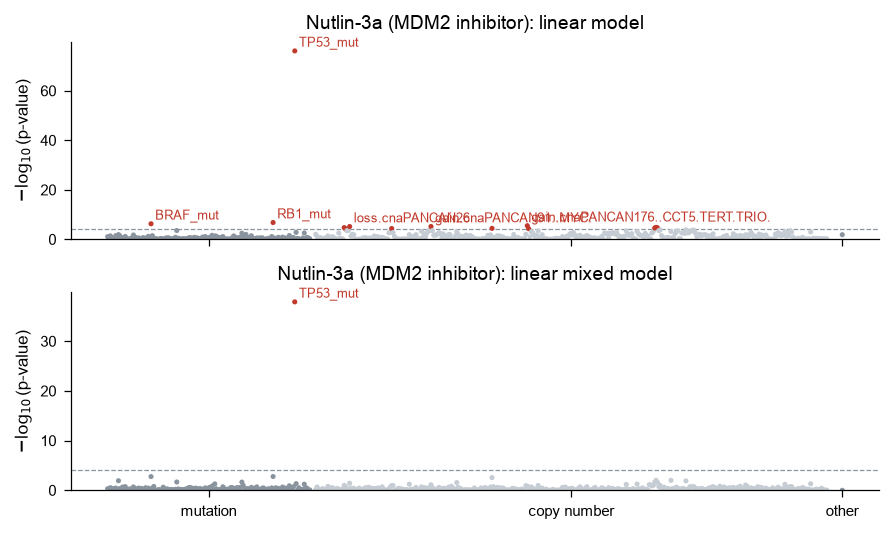

In [10]:
def manhattan_pair(lm, lmm, phenotype, title, feature_type=feature_type):
    fig, axes = plt.subplots(2, 1, figsize=(6, 3.6), sharex=True)
    for ax, result, name in zip(axes, [lm, lmm], ["linear model", "linear mixed model"]):
        pv = result.pvalue[phenotype].dropna()
        cmix.plot.manhattan(pv, chrom=feature_type[pv.index].to_numpy(), ax=ax, max_labels=6)
        ax.set_title(f"{title}: {name}")
    plt.tight_layout()
    return axes


manhattan_pair(drug_lm, drug_lmm, "1047;Nutlin-3a (-);GDSC1", "Nutlin-3a (MDM2 inhibitor)");

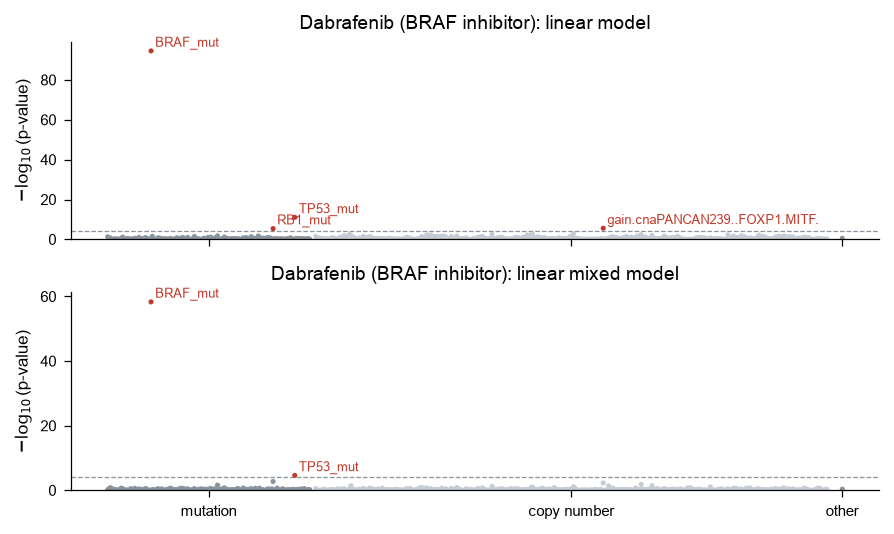

In [11]:
manhattan_pair(drug_lm, drug_lmm, "1373;Dabrafenib;GDSC1", "Dabrafenib (BRAF inhibitor)");

## CRISPR-Cas9 gene essentiality

Here every one of the 17,486 genes is a phenotype. All CRISPR screens share (almost) the same
cell lines, so the linear model scan reduces to a single matrix product and the mixed model scan
to one variance component fit per gene on a shared eigendecomposition of the kinship matrix.

In [12]:
samples = crispr.index.intersection(genomics.index)
Y_crispr = crispr.loc[samples]
G_crispr = genomics.loc[samples].loc[:, genomics.loc[samples].sum() >= 10]
M_crispr = covariates.loc[samples].assign(broad=(institute.reindex(samples) == "Broad").astype(float))
K_crispr = K.loc[samples, samples]
print(f"{len(samples)} cell lines, {G_crispr.shape[1]} genomic features, {Y_crispr.shape[1]} genes")

535 cell lines, 395 genomic features, 17486 genes


In [13]:
start = time.perf_counter()
crispr_lm = cmix.scan(Y_crispr, G_crispr, M=M_crispr)
timings["CRISPR-Cas9, LM"] = time.perf_counter() - start

start = time.perf_counter()
crispr_lmm = cmix.scan(Y_crispr, G_crispr, K=K_crispr, M=M_crispr)
timings["CRISPR-Cas9, LMM"] = time.perf_counter() - start

print(crispr_lm, crispr_lmm, sep="\n\n")

ScanResult: 17486 phenotype(s) x 395 variant(s) in 1.38 s
  linear model (no kinship)
  smallest p-value: 2.55e-105

ScanResult: 17486 phenotype(s) x 395 variant(s) in 70.79 s
  h2 (median): 0.020
  smallest p-value: 3.01e-62


/tmp/ipykernel_395955/3222188856.py:9: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


,tests,Bonferroni hits (5%),fraction p < 1e-3,median -log10 p / expected
LM,6906970.0,302.0,0.003310,1.081256
LMM,6906970.0,105.0,0.001509,0.994337


/data/tmpC/cmix/.venv/lib/python3.13/site-packages/IPython/core/events.py:101: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


/data/tmpC/cmix/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


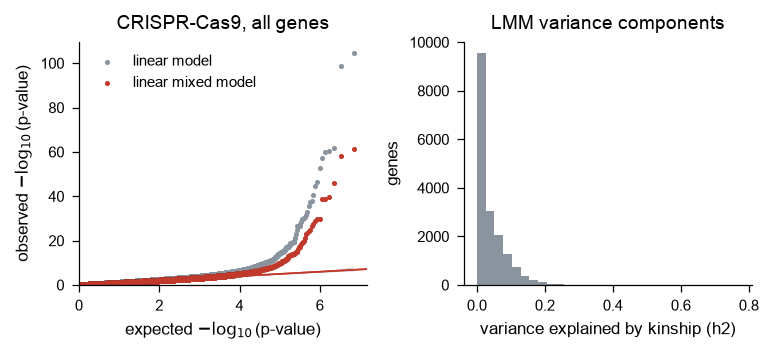

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(5.2, 2.4))
cmix.plot.qqplot(flat(crispr_lm), ax=axes[0], label="linear model", color=GREY)
cmix.plot.qqplot(flat(crispr_lmm), ax=axes[0], label="linear mixed model", color=RED)
axes[0].set_title("CRISPR-Cas9, all genes")
axes[1].hist(crispr_lmm.variances["h2"].dropna(), bins=30, color=GREY)
axes[1].set_xlabel("variance explained by kinship (h2)")
axes[1].set_ylabel("genes")
axes[1].set_title("LMM variance components")
plt.tight_layout()
summarise({"LM": crispr_lm, "LMM": crispr_lmm})

### Strongest associations

Oncogene addiction dominates the top of the list: KRAS-, BRAF- and NRAS-mutant lines depend on
the mutated gene itself, TP53 wild-type lines depend on MDM2 (positive effect of TP53 mutation on
MDM2 gene effect), and so on. For 17,486 x 500+ tests the long table has about 9 million rows, so
the wide tables are used for filtering and only the top rows are expanded.

In [15]:
pv = crispr_lmm.pvalue.to_numpy()
idx = np.argsort(pv, axis=None)[:15]
rows, cols = np.unravel_index(idx, pv.shape)
top_crispr = pd.DataFrame({
    "gene": crispr_lmm.pvalue.columns[cols],
    "feature": crispr_lmm.pvalue.index[rows],
    "beta": crispr_lmm.beta.to_numpy()[rows, cols],
    "beta_se": crispr_lmm.beta_se.to_numpy()[rows, cols],
    "pvalue": pv[rows, cols],
    "pvalue_lm": crispr_lm.pvalue.to_numpy()[rows, cols],
    "h2": crispr_lmm.variances["h2"].to_numpy()[cols],
})
top_crispr

,gene,feature,beta,beta_se,pvalue,pvalue_lm,h2
0,KRAS,KRAS_mut,-1.807277,0.095359,3.007239e-62,2.548163e-105,0.711740
1,NRAS,NRAS_mut,-1.927591,0.105217,4.099168e-59,1.235796e-99,0.771086
2,BRAF,BRAF_mut,-1.171024,0.074280,1.000000e-46,2.325352e-62,0.501435
3,FLI1,EWSR1.FLI1_mut,-1.655146,0.115019,2.499953e-40,1.140115e-53,0.435988
4,TP53,TP53_mut,-0.753517,0.053012,1.584780e-39,7.737901e-61,0.496923
5,MYCN,gain.cnaPANCAN344..MYCN.,-1.543098,0.108682,1.871418e-39,3.311791e-61,0.519843
6,STAG1,STAG2_mut,-1.222426,0.100271,1.181452e-30,2.538163e-32,0.319359
7,MDM2,TP53_mut,0.810861,0.066997,2.776742e-30,2.032425e-45,0.396560
8,PIK3CA,PIK3CA_mut,-0.914935,0.076320,8.382163e-30,8.850331e-39,0.464509
9,MDM4,TP53_mut,0.496304,0.042898,4.495658e-28,3.422269e-36,0.248501


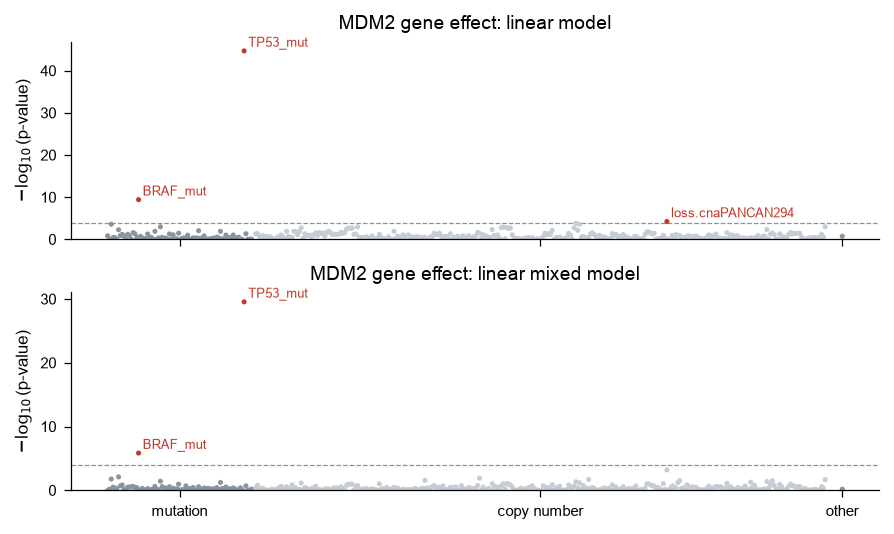

In [16]:
manhattan_pair(crispr_lm, crispr_lmm, "MDM2", "MDM2 gene effect");

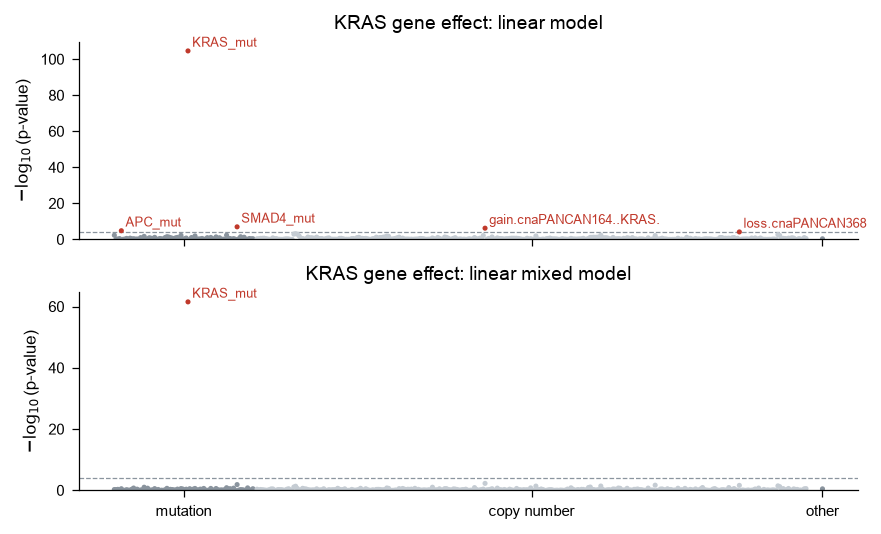

In [17]:
manhattan_pair(crispr_lm, crispr_lmm, "KRAS", "KRAS gene effect");

## Timing

Wall-clock time of `cmix.scan` for each analysis (data loading excluded). The mixed model pays
for one variance component fit per phenotype and, for the drug response, one eigendecomposition
per distinct set of screened cell lines (515 patterns for 819 drugs). The linear model scan of the
CRISPR data is essentially a single BLAS matrix product over 7 million tests.

`cmix.scan` caps the BLAS thread pool at 8 threads by default (`threads=` argument): the
matrices are small and letting OpenBLAS use all 48 cores of this server made the drug response
mixed model scan more than ten times slower.

In [18]:
import os, platform

summary = pd.DataFrame({
    "tests": {
        "drug response, LM": int(np.isfinite(drug_lm.pvalue.to_numpy()).sum()),
        "drug response, LMM": int(np.isfinite(drug_lmm.pvalue.to_numpy()).sum()),
        "CRISPR-Cas9, LM": int(np.isfinite(crispr_lm.pvalue.to_numpy()).sum()),
        "CRISPR-Cas9, LMM": int(np.isfinite(crispr_lmm.pvalue.to_numpy()).sum()),
    },
    "seconds": timings,
})
summary["tests per second"] = (summary["tests"] / summary["seconds"]).round(0)
print(f"{platform.processor() or platform.machine()}, {os.cpu_count()} cores, numpy {np.__version__}")
summary

x86_64, 48 cores, numpy 2.5.4


,tests,seconds,tests per second
"drug response, LM",430416,1.603683,268392.0
"drug response, LMM",430416,32.854495,13101.0
"CRISPR-Cas9, LM",6906970,1.458422,4735920.0
"CRISPR-Cas9, LMM",6906970,70.868243,97462.0
